<a href="https://colab.research.google.com/github/MashrufAhmed-470/machine-learning/blob/main/COMP4980_ML_FINAL_PROJECT_MashrufAhmedZafri.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

COMP 4980 ML Final Project

Mashruf Ahmed Zafri

T00657643

Importing necessary libraries that are used for data manipulation and visualization. The machine learning models (Random Forest, MLP, Decision Tree) and techniques (PCA, cross-validation) are imported from sklearn to be applied for regression and analysis.

In [ ]:
# Importing necessary libraries for data processing, modeling, and visualization
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_squared_error
from sklearn.neural_network import MLPRegressor
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.model_selection import cross_val_score

1. Data Loading and Cleaning

In [ ]:
# Load the dataset
dataset_path = '/content/vehicles.csv'
data = pd.read_csv(dataset_path)

# Display basic dataset information
print("Dataset shape:", data.shape)
print("Missing values:\n", data.isnull().sum())
print("Column names:", data.columns)
print(data.info())

# Handle missing values in the 'drive' column
data['drive'] = data['drive'].replace('nan', np.nan)
most_frequent_drive = data['drive'].mode()[0]
data['drive'].fillna(most_frequent_drive, inplace=True)

# Verify missing values are handled
print(f"Missing values in 'drive': {data['drive'].isnull().sum()}")

Dataset shape: (42230, 83)
Missing values:
 barrels08         0
barrelsA08        0
charge120         0
charge240         0
city08            0
              ...  
modifiedOn        0
startStop     31704
phevCity          0
phevHwy           0
phevComb          0
Length: 83, dtype: int64
Column names: Index(['barrels08', 'barrelsA08', 'charge120', 'charge240', 'city08',
       'city08U', 'cityA08', 'cityA08U', 'cityCD', 'cityE', 'cityUF', 'co2',
       'co2A', 'co2TailpipeAGpm', 'co2TailpipeGpm', 'comb08', 'comb08U',
       'combA08', 'combA08U', 'combE', 'combinedCD', 'combinedUF', 'cylinders',
       'displ', 'drive', 'engId', 'eng_dscr', 'feScore', 'fuelCost08',
       'fuelCostA08', 'fuelType', 'fuelType1', 'ghgScore', 'ghgScoreA',
       'highway08', 'highway08U', 'highwayA08', 'highwayA08U', 'highwayCD',
       'highwayE', 'highwayUF', 'hlv', 'hpv', 'id', 'lv2', 'lv4', 'make',
       'model', 'mpgData', 'phevBlended', 'pv2', 'pv4', 'range', 'rangeCity',
       'rangeCityA', 'rang

<ipython-input-23-c378bc6c6520>:3: DtypeWarning: Columns (70,71,72,73,74,76,79) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv(dataset_path)
<ipython-input-23-c378bc6c6520>:14: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['drive'].fillna(most_frequent_drive, inplace=True)


2. Feature Engineering and Selection

We create two derived features:

Fuel Efficiency Ratio: This feature is the ratio of highway fuel economy to city fuel economy, which provides additional insight into a vehicle's fuel efficiency on highways versus city driving.

Engine Power Ratio: This feature compares the number of cylinders to engine displacement, which can help measure how powerful the engine is relative to its size.

In [ ]:
# Create new derived features
data['fuel_efficiency_ratio'] = data['highway08'] / data['city08']
data['engine_power_ratio'] = data['cylinders'] / data['displ']

# Select relevant features for the analysis of predicting CO₂ emissions
relevant_features = ['co2', 'comb08', 'city08', 'highway08', 'displ', 'cylinders',
                     'barrels08', 'fuel_efficiency_ratio', 'engine_power_ratio']
data = data[relevant_features].dropna()

# Define features (X) and target (y)
X = data.drop(columns=['co2'])
y = data['co2']

3. Exploratory Data Analysis (EDA)

3.1 Histograms

This code visualizes the distribution of CO₂ emissions and combined fuel economy across the dataset using histograms.

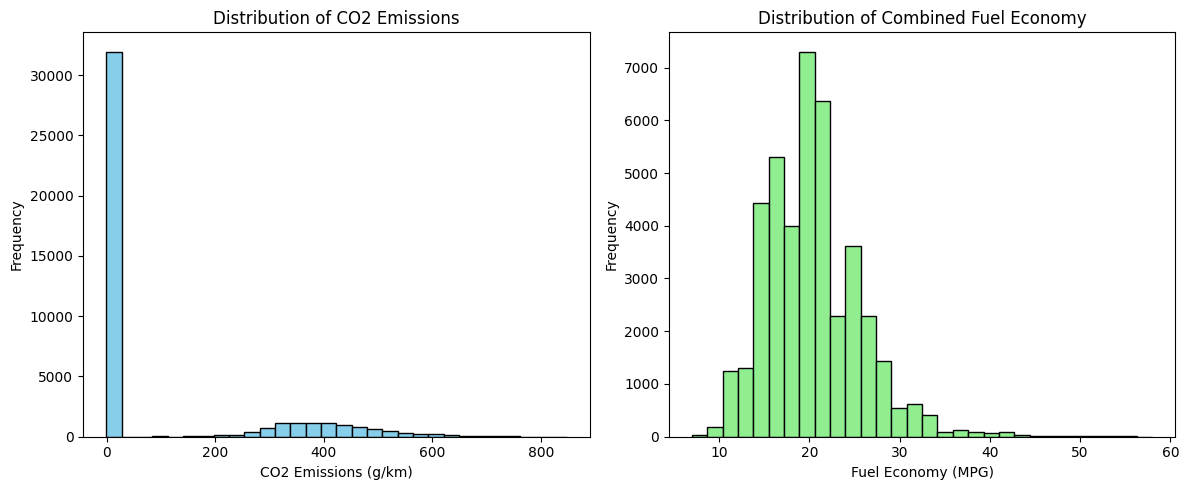

In [ ]:
# Visualize distributions of CO2 emissions and combined fuel economy
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(data['co2'], bins=30, color='skyblue', edgecolor='black')
plt.title('Distribution of CO2 Emissions')
plt.xlabel('CO2 Emissions (g/km)')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
plt.hist(data['comb08'], bins=30, color='lightgreen', edgecolor='black')
plt.title('Distribution of Combined Fuel Economy')
plt.xlabel('Fuel Economy (MPG)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

3.2 Scatter Plots

Scatter plots help visualize relationships between key features like engine displacement, fuel efficiency ratio, and CO₂ emissions.

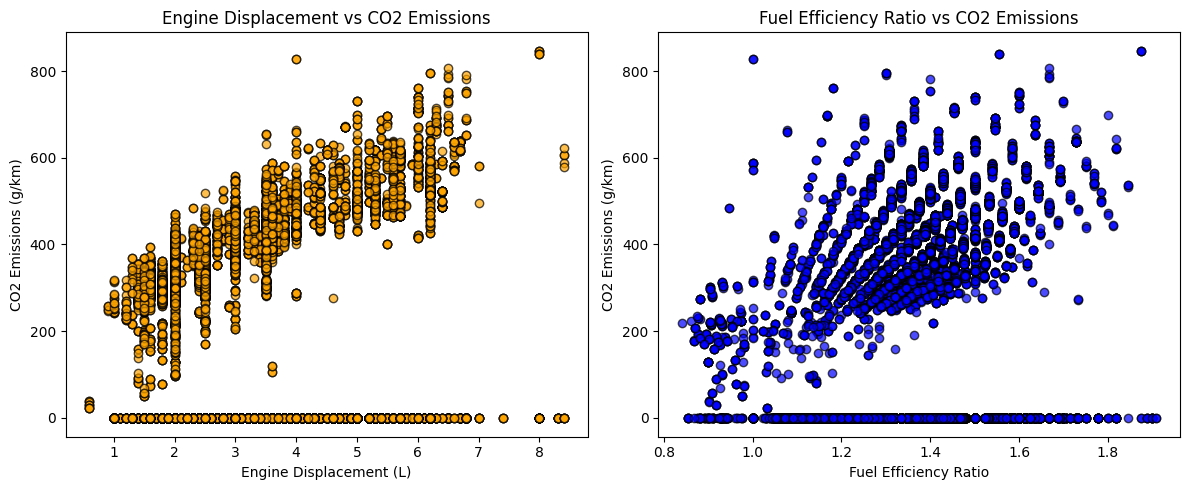

In [ ]:
# Scatter plots to explore relationships
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(data['displ'], data['co2'], alpha=0.7, color='orange', edgecolor='k')
plt.title('Engine Displacement vs CO2 Emissions')
plt.xlabel('Engine Displacement (L)')
plt.ylabel('CO2 Emissions (g/km)')

plt.subplot(1, 2, 2)
plt.scatter(data['fuel_efficiency_ratio'], data['co2'], alpha=0.7, color='blue', edgecolor='k')
plt.title('Fuel Efficiency Ratio vs CO2 Emissions')
plt.xlabel('Fuel Efficiency Ratio')
plt.ylabel('CO2 Emissions (g/km)')

plt.tight_layout()
plt.show()

3.3 Correlation Heatmap

A correlation heatmap helps visualize how strongly each feature is correlated with others.

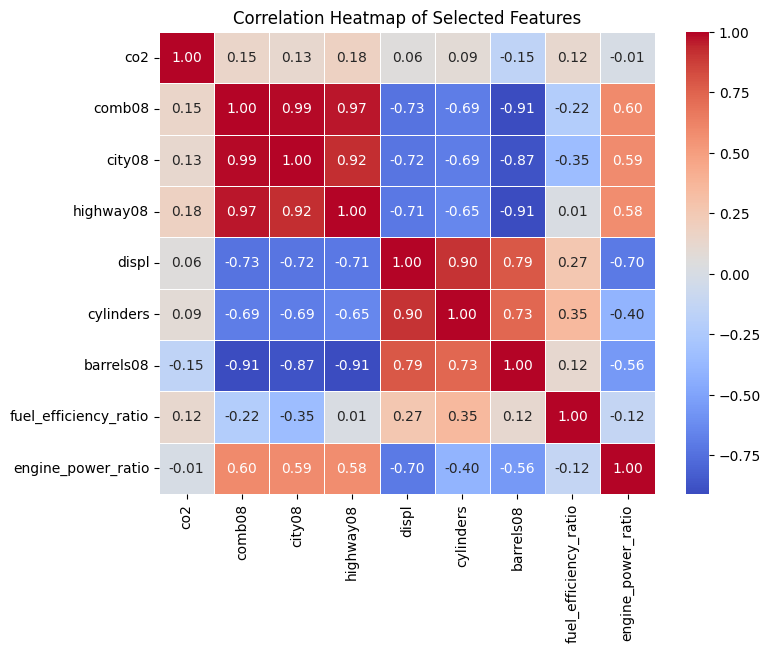

In [ ]:
# Correlation heatmap for selected features
correlation_matrix = data.corr()
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title('Correlation Heatmap of Selected Features')
plt.show()

4. Preprocessing Pipeline

The features are standardized to ensure that all numerical features have the same scale.

In [ ]:
# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), X.columns)  # Standardize numerical features
    ]
)

# Apply preprocessing pipeline
X_transformed = preprocessor.fit_transform(X)

5. Machine Learning Models

5.1 Train-Test Split

In [ ]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_transformed, y, test_size=0.3, random_state=42)

5.2 Random Forest with RandomizedSearchCV

Hyperparameter tuning for the Random Forest model using RandomizedSearchCV

In [ ]:
# Random Forest Parameter Grid
param_dist_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
}

# RandomizedSearchCV
rf_model = RandomForestRegressor(random_state=42)
rf_random_search = RandomizedSearchCV(
    estimator=rf_model, param_distributions=param_dist_rf,
    n_iter=20, cv=3, scoring='neg_mean_squared_error', verbose=2, random_state=42
)
rf_random_search.fit(X_train, y_train)

# Evaluate the best Random Forest model
best_rf = rf_random_search.best_estimator_
y_pred_rf = best_rf.predict(X_test)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
print(f"Best Random Forest RMSE: {rmse_rf}")

Fitting 3 folds for each of 20 candidates, totalling 60 fits
[CV] END max_depth=20, min_samples_leaf=4, min_samples_split=5, n_estimators=200; total time=   6.5s
[CV] END max_depth=20, min_samples_leaf=4, min_samples_split=5, n_estimators=200; total time=   6.8s
[CV] END max_depth=20, min_samples_leaf=4, min_samples_split=5, n_estimators=200; total time=   6.7s
[CV] END max_depth=5, min_samples_leaf=2, min_samples_split=2, n_estimators=100; total time=   1.8s
[CV] END max_depth=5, min_samples_leaf=2, min_samples_split=2, n_estimators=100; total time=   3.5s
[CV] END max_depth=5, min_samples_leaf=2, min_samples_split=2, n_estimators=100; total time=   2.0s
[CV] END max_depth=5, min_samples_leaf=1, min_samples_split=5, n_estimators=100; total time=   1.5s
[CV] END max_depth=5, min_samples_leaf=1, min_samples_split=5, n_estimators=100; total time=   1.5s
[CV] END max_depth=5, min_samples_leaf=1, min_samples_split=5, n_estimators=100; total time=   1.9s
[CV] END max_depth=None, min_samples

/usr/local/lib/python3.10/dist-packages/numpy/ma/core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


Best Random Forest RMSE: 129.91380768226367


5.3 Multi-Layer Perceptron with RandomizedSearchCV

In [ ]:
# MLP Parameter Grid
param_dist_mlp = {
    'hidden_layer_sizes': [(50,), (100,), (100, 50)],
    'alpha': [0.0001, 0.001, 0.01],
    'max_iter': [200, 500],
}

# RandomizedSearchCV
mlp_model = MLPRegressor(random_state=42)
mlp_random_search = RandomizedSearchCV(
    estimator=mlp_model, param_distributions=param_dist_mlp,
    n_iter=20, cv=3, scoring='neg_mean_squared_error', verbose=2, random_state=42
)
mlp_random_search.fit(X_train, y_train)

# Evaluate the best MLP model
best_mlp = mlp_random_search.best_estimator_
y_pred_mlp = best_mlp.predict(X_test)
rmse_mlp = np.sqrt(mean_squared_error(y_test, y_pred_mlp))
print(f"Best MLP RMSE: {rmse_mlp}")

/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_search.py:320: UserWarning: The total space of parameters 18 is smaller than n_iter=20. Running 18 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Fitting 3 folds for each of 18 candidates, totalling 54 fits


/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


[CV] END alpha=0.0001, hidden_layer_sizes=(50,), max_iter=200; total time=  15.4s


/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


[CV] END alpha=0.0001, hidden_layer_sizes=(50,), max_iter=200; total time=  15.3s


... (84 outputs left out)

/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


[CV] END alpha=0.01, hidden_layer_sizes=(100, 50), max_iter=200; total time=  36.0s
[CV] END alpha=0.01, hidden_layer_sizes=(100, 50), max_iter=500; total time= 1.5min
[CV] END alpha=0.01, hidden_layer_sizes=(100, 50), max_iter=500; total time= 1.4min
[CV] END alpha=0.01, hidden_layer_sizes=(100, 50), max_iter=500; total time= 1.4min


/usr/local/lib/python3.10/dist-packages/numpy/ma/core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


Best MLP RMSE: 149.47677590819808


6. Model Comparison

Comparing the RMSE values of the two models (Random Forest and MLP) by plotting them on a bar chart. The model with the lower RMSE value is considered better, and this comparison helps visualize the relative performance of the two models in predicting CO₂ emissions.

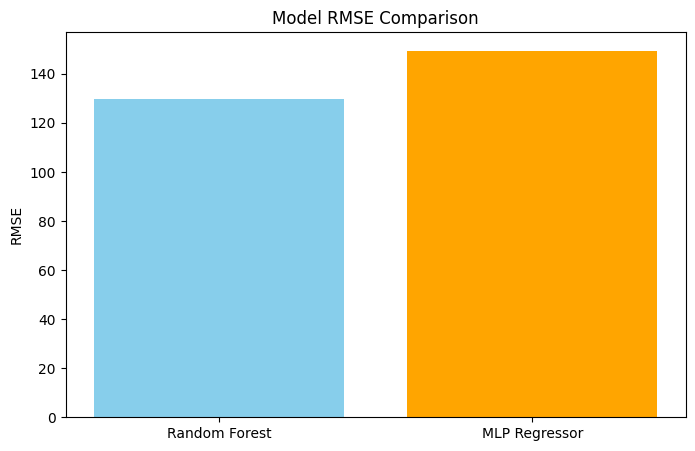

In [ ]:
# Compare RMSE values
models_rmse = {'Random Forest': rmse_rf, 'MLP Regressor': rmse_mlp}
plt.figure(figsize=(8, 5))
plt.bar(models_rmse.keys(), models_rmse.values(), color=['skyblue', 'orange'])
plt.title('Model RMSE Comparison')
plt.ylabel('RMSE')
plt.show()

7. PCA Visualization

 Principal Component Analysis (PCA) is applied to reduce the dimensionality of the dataset.

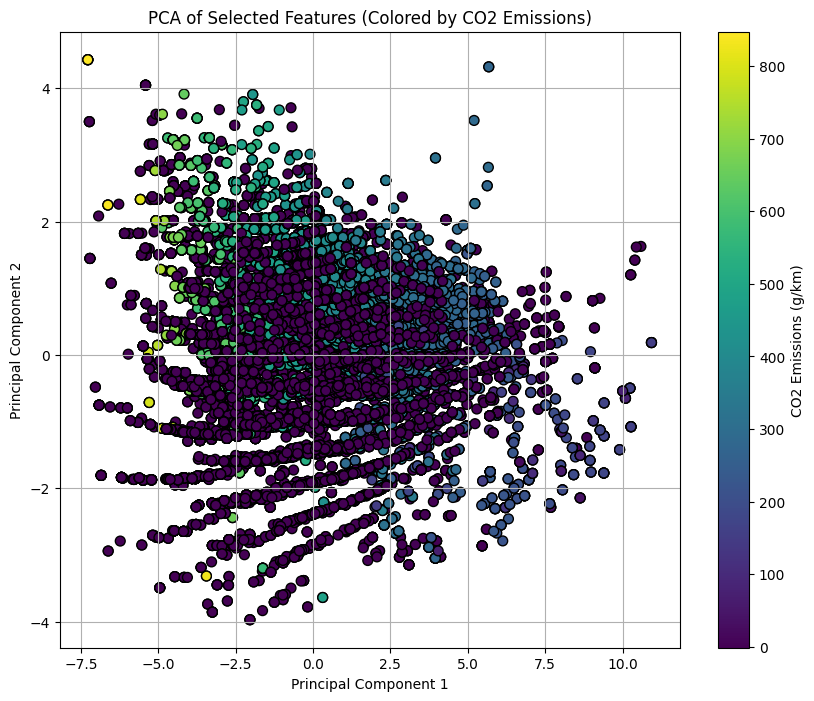

In [ ]:
# Apply PCA for better visualization
pca = PCA(n_components=2)
X_pca_result = pca.fit_transform(X_transformed)

# Plot PCA results with clearer visualization
plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_pca_result[:, 0], X_pca_result[:, 1], c=y, cmap='viridis', edgecolor='k', s=50)
plt.title("PCA of Selected Features (Colored by CO2 Emissions)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="CO2 Emissions (g/km)")
plt.grid(True)
plt.show()

This code applies cross-validation to evaluate the performance of the best Random Forest model. By splitting the data into multiple folds, cross-validation helps ensure the model’s reliability and reduces the likelihood of overfitting. The RMSE is calculated for each fold and averaged.

In [ ]:
cv_scores = cross_val_score(best_rf, X_transformed, y, cv=5, scoring='neg_mean_squared_error')
print(f"Cross-Validation RMSE: {np.sqrt(-cv_scores.mean()):.3f}")

Cross-Validation RMSE: 185.117


This section trains a simple decision tree model (with a maximum depth of 3) to predict CO₂ emissions. The decision tree helps us understand which features are the most influential in predicting emissions by splitting the data based on the most important features.

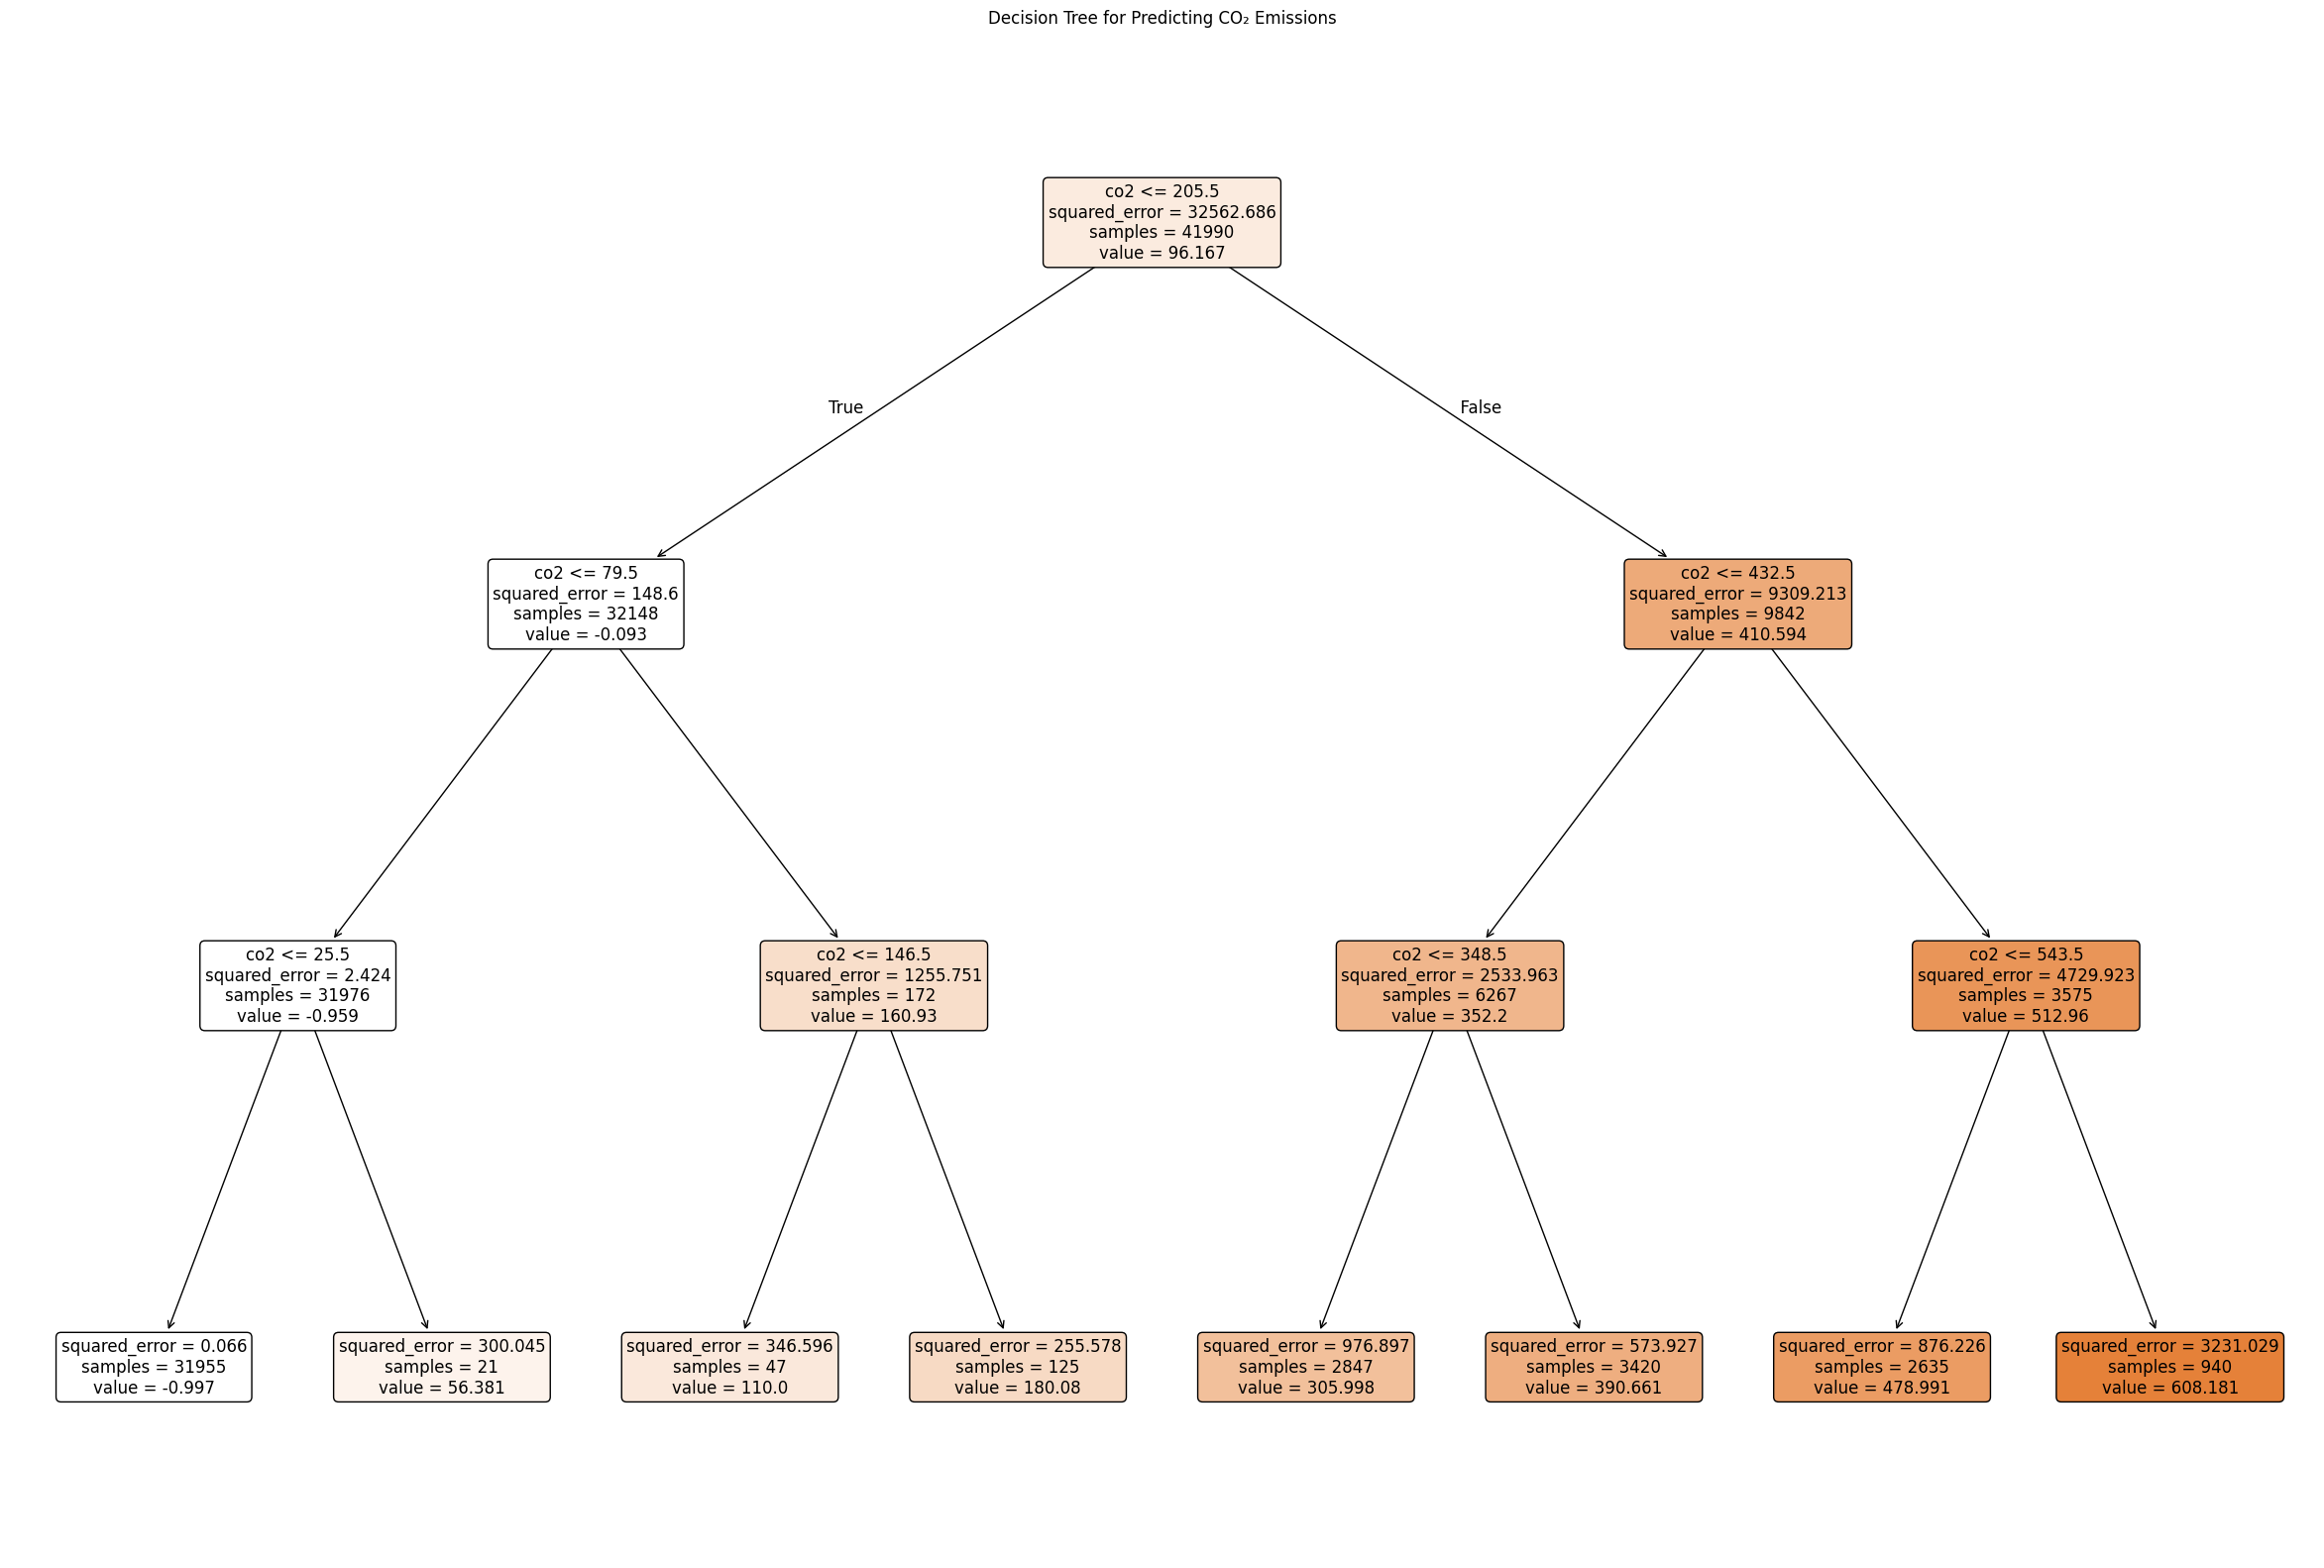

In [ ]:
# Train a decision tree model
X = data.select_dtypes(include=[np.number])  # Use only numerical data
y = data['co2']
dt_model = DecisionTreeRegressor(max_depth=3)  # Limit tree depth to 3 for better visualization
dt_model.fit(X, y)

# Plot the decision tree
plt.figure(figsize=(30, 20))
plot_tree(dt_model, feature_names=X.columns, filled=True, rounded=True, fontsize=12)
plt.title('Decision Tree for Predicting CO₂ Emissions')
plt.show()